In [2]:
!pip install kagglehub

In [3]:
import kagglehub

path = kagglehub.dataset_download('dskagglemt/student-performance-data-set')
print(path)

Using Colab cache for faster access to the 'student-performance-data-set' dataset.
/kaggle/input/student-performance-data-set


In [4]:
import os
print(os.listdir(path))

['student-mat.csv', 'student-merge.R', 'student-por.csv', 'student.txt']


In [5]:
import pandas as pd
data= pd.read_csv(path+"/student-mat.csv", sep=';' )
print(data.shape)
data.head()


(395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [29]:
data.info()
data["G3"].describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 42 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   age                395 non-null    int64
 1   Medu               395 non-null    int64
 2   Fedu               395 non-null    int64
 3   traveltime         395 non-null    int64
 4   studytime          395 non-null    int64
 5   failures           395 non-null    int64
 6   famrel             395 non-null    int64
 7   freetime           395 non-null    int64
 8   goout              395 non-null    int64
 9   Dalc               395 non-null    int64
 10  Walc               395 non-null    int64
 11  health             395 non-null    int64
 12  absences           395 non-null    int64
 13  G1                 395 non-null    int64
 14  G2                 395 non-null    int64
 15  G3                 395 non-null    int64
 16  school_MS          395 non-null    bool 
 17  sex_M           

,G3
count,395.000000
mean,10.415190
std,4.581443
min,0.000000
25%,8.000000
50%,11.000000
75%,14.000000
max,20.000000


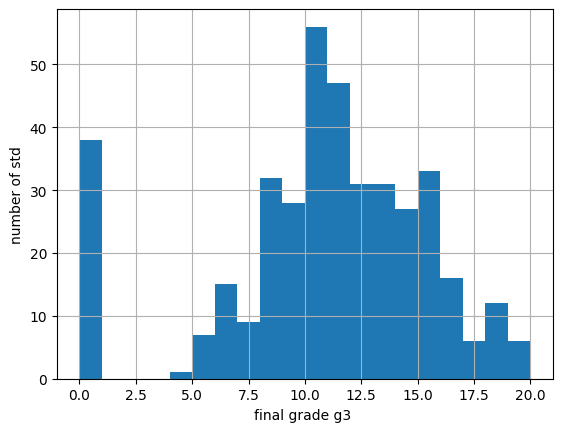

In [7]:
import matplotlib.pyplot as plt
data["G3"].hist(bins =20 )
plt.xlabel("final grade g3 ")
plt.ylabel("number of std")
plt.show()



In [8]:
data = pd.get_dummies(data , drop_first=True)

print(data.shape)

(395, 42)


In [9]:
data.head()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,True,False,True,False,False,False,True,True,False,False
1,17,1,1,1,2,0,5,3,3,1,...,False,False,False,True,False,False,False,True,True,False
2,15,1,1,1,2,3,4,3,2,2,...,True,False,True,False,True,False,True,True,True,False
3,15,4,2,1,3,0,3,2,2,1,...,True,False,False,True,True,True,True,True,True,True
4,16,3,3,1,2,0,4,3,2,1,...,False,False,False,True,True,False,True,True,False,False


In [18]:
from sklearn.model_selection import train_test_split
X = data.drop("G3" , axis=1)
y = data["G3"]

x_train  , x_test, y_train ,y_test = train_test_split(X ,y , test_size=0.2 , random_state=42)

print(x_train.shape)
print(x_test.shape)

(316, 41)
(79, 41)


In [19]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [20]:
model.fit(x_train,y_train)

LinearRegression()

In [25]:
prediction = model.predict(x_test)
print(prediction[:5])
print("*****************************")
print(y_test[:5].values)

[ 6.00160699 11.52847844  2.86643677  8.79663116  8.55310627]
*****************************
[10 12  5 10  9]


In [26]:
from sklearn.metrics import r2_score , mean_absolute_error
print("r2" ,r2_score(y_test,prediction))
print(mean_absolute_error(y_test,prediction))

r2 0.7241341236974022
1.6466656197147511


In [28]:
import pandas as pd
w = pd.Series(model.coef_ , index=X.columns).sort_values()
print(w)

reason_home         -0.611901
activities_yes      -0.517500
Mjob_health         -0.463244
romantic_yes        -0.390353
Fjob_services       -0.294762
failures            -0.285781
Mjob_other          -0.237195
nursery_yes         -0.236861
reason_reputation   -0.221694
Dalc                -0.185509
internet_yes        -0.168204
Fedu                -0.167378
guardian_other      -0.149291
Pstatus_T           -0.140394
age                 -0.115927
Fjob_teacher        -0.068291
Mjob_services       -0.051643
freetime            -0.020226
famsize_LE3         -0.008772
studytime           -0.007743
health               0.044027
Walc                 0.053906
absences             0.055593
paid_yes             0.067222
address_U            0.082612
Medu                 0.086317
traveltime           0.088593
school_MS            0.093814
guardian_mother      0.095304
Mjob_teacher         0.099152
goout                0.189859
famsup_yes           0.203656
Fjob_other           0.206441
G1        